# Question 1.

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

import warnings
warnings.filterwarnings("ignore")

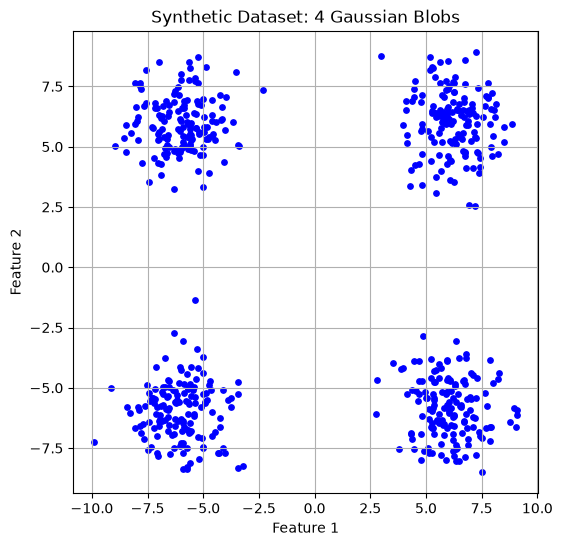

In [14]:
X, y_true = make_blobs(n_samples=600,
                       centers=[[-6, -6], [-6, 6], [6, -6], [6, 6]],
                       cluster_std=1.2, random_state=42)

plt.figure(figsize=(6, 6))
plt.scatter(X[:, 0], X[:, 1], s=15, color='blue')
plt.title('Synthetic Dataset: 4 Gaussian Blobs')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.grid(True)
plt.show()

## (a) Ordinary k-means with random initialization (10 runs)

In [15]:
k = 4
random_runs = []
for seed in range(10):
    km = KMeans(n_clusters=k, init='random', n_init=1, random_state=seed).fit(X)
    random_runs.append(km)
    print(f"seed {seed}: SSE = {km.inertia_:9.2f}")

sse = np.array([km.inertia_ for km in random_runs])
poor_run = random_runs[np.argmax(sse)]
good_run = random_runs[np.argmin(sse)]
print(f"\nPoor run: seed {np.argmax(sse)} (SSE = {sse.max():.2f})")
print(f"Good run: seed {np.argmin(sse)} (SSE = {sse.min():.2f})")

seed 0: SSE =   1677.30
seed 1: SSE =  12105.01
seed 2: SSE =  12101.42
seed 3: SSE =   1677.30
seed 4: SSE =   1677.30
seed 5: SSE =   1677.30
seed 6: SSE =   1677.30
seed 7: SSE =   1677.30
seed 8: SSE =   1677.30
seed 9: SSE =  12187.64

Poor run: seed 9 (SSE = 12187.64)
Good run: seed 0 (SSE = 1677.30)


**Poor run:** seed 9 (SSE ≈ 12188). **good run:** seed 0 (SSE ≈ 1677).

## (b) k-means++

 I implemented the k-means++ seeding myself then passed those centers to scikit-learn's `KMeans` to run the regular k-means iterations.

In [16]:
def kmeans_pp_init(X, k, random_state=0):
    rng = np.random.default_rng(random_state)
    n = X.shape[0]
    # Step 1: first center uniformly at random from the data
    centers = [X[rng.integers(n)]]
    while len(centers) < k:
        # Step 2: D(p)^2 = squared distance from each point to its nearest chosen center
        d2 = np.min(((X[:, None, :] - np.array(centers)[None, :, :]) ** 2).sum(axis=2), axis=1)
        # Step 3: pick next center with probability proportional to D(p)^2
        probs = d2 / d2.sum()
        centers.append(X[rng.choice(n, p=probs)])
    return np.array(centers)

init_centers = kmeans_pp_init(X, k, random_state=0)
pp_run = KMeans(n_clusters=k, init=init_centers, n_init=1).fit(X)
print("k-means++ initial centers:\n", np.round(init_centers, 2))
print(f"k-means++ SSE = {pp_run.inertia_:.2f}")

k-means++ initial centers:
 [[-6.86 -5.18]
 [ 7.66 -5.22]
 [-7.58  8.2 ]
 [ 7.04  6.59]]
k-means++ SSE = 1677.30


## (c) Dataset and the three clusterings

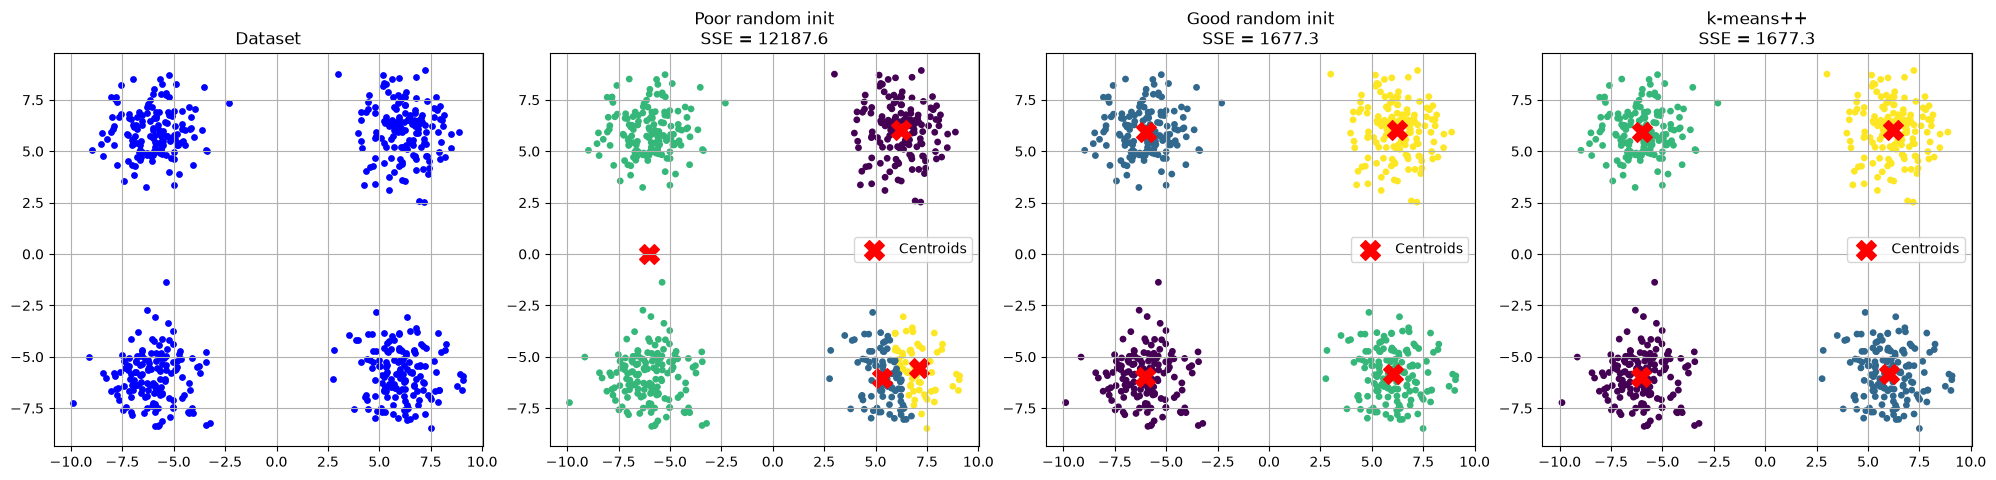

In [17]:
runs = [(None, "Dataset"),
        (poor_run, "Poor random init"),
        (good_run, "Good random init"),
        (pp_run, "k-means++")]

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, (km, title) in zip(axes, runs):
    if km is None:
        ax.scatter(X[:, 0], X[:, 1], s=15, color='blue')
    else:
        ax.scatter(X[:, 0], X[:, 1], c=km.labels_, cmap='viridis', s=15)
        ax.scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1],
                   c='red', s=200, marker='X', label='Centroids')
        ax.legend()
        title += f"\nSSE = {km.inertia_:.1f}"
    ax.set_title(title)
    ax.set_aspect('equal')
    ax.grid(True)

plt.tight_layout()
plt.show()

## (d) Within-cluster SSE

In [18]:
for km, name in runs[1:]:
    print(f"{name:18s} SSE = {km.inertia_:.2f}")

Poor random init   SSE = 12187.64
Good random init   SSE = 1677.30
k-means++          SSE = 1677.30


| Run | Within-cluster SSE |
|---|---|
| Poor random init (seed 9) | 12187.64 |
| Good random init (seed 0) | 1677.30 |
| k-means++ | 1677.30 |

## (e) Observations

k-means only finds a local minimum  so the result depends on where it starts. In the poor run, two starting centers landed in the same bottom-right blob, so that blob was split in two. To make up for it, one centroid ended up in the empty middle, covering two blobs at once. K-means++ helps mitigate initialization sensitivity by selecting each new cluster center with a probability proportional to its squared distance from existing centers, ensuring distant points in separate clusters are chosen. 